# NOTEBOOK 7 (CORRECTED): Pathway analysis — GSEA and ORA — OSD-420

**The Spleen Machine (OSD-420-3)**

Run **Notebook 6 (corrected) first** — this notebook reads its outputs from `results/`.
If you change a parameter in Notebook 6 you must re-run this notebook too; parameter drift
between the two is a named course mistake.

---

## What was wrong with the previous run, and what changed

| # | Previous version | Why it was wrong | This version |
|---|---|---|---|
| 1 | `run_ora()` took a `background_genes` argument and **never passed it to `gp.enrichr`** | Every ORA p-value was computed against Enrichr's whole-genome default (~20,000 genes) instead of the genes actually tested. The markdown claimed the opposite. | `gp.enrichr(..., background=background)` — and the background is the **tested** set. |
| 2 | `permutation_type='gene_set'`, with the notebook's own comment saying to use phenotype at n ≥ 15 | Gene-set permutation destroys gene–gene correlation structure, so any co-regulated block — such as one contaminating tissue — scores as wildly significant. There are 20 samples. | `permutation_type='phenotype'` |
| 3 | GSEA run on **raw** counts | `signal_to_noise` on raw counts conflates expression with library size. | Run on **DESeq2 normalised counts**. |
| 4 | `min_size=5` on GO, gseapy default of 15 on GEO, `max_size` never set | Drift inside one notebook, and 500+ member sets eligible against a 10-gene list. | `min_size=15`, `max_size=300`, the same for every library. |
| 5 | Terms filtered on FWER alone | Terms at FDR q = 0.27 and q = 0.35 were reported as significant. | **FDR q < 0.25 AND FWER < 0.25.** |
| 6 | `display_cols` excluded `Overlap` | Gene-set size and fold enrichment could not be reported at all — both are required by the course. | Overlap, set size, **fold enrichment** and odds ratio all reported. |
| 7 | Six of ten reported GO terms were **single-gene** overlaps, and the gene was APOA2 (a contaminant) | A one-gene overlap is not an enrichment; it is that gene's annotation with a p-value attached. | Terms with fewer than 3 overlapping genes are dropped. |
| 8 | `!cat go_gsea_results.csv` where `geo_` was meant | The GEO results were computed and never looked at. | Every result set is displayed. |
| 9 | `title=terms.iloc[0]` inside a loop over `i` | All eleven heatmaps carried the same title. | `terms.iloc[i]`. |
| 10 | Enrichment tables reported without checking member genes | The lecture calls the download-back-to-your-data loop the single most important procedural step. | Every reported term's member genes are written out with their real log₂FC and adjusted p. |

In [1]:
!pip install -q gseapy==1.3.1

import os
import numpy as np, pandas as pd, gseapy as gp
from scipy import stats
import matplotlib.pyplot as plt

OUT = "results"; os.makedirs(f"{OUT}/pathways", exist_ok=True)

ALPHA       = 0.05    # must match Notebook 6
FDR_T       = 0.25
FWER_T      = 0.25
MIN_SET     = 15      # smallest gene set worth testing
MAX_SET     = 300     # largest -- avoids 500+ member sets against a small list
MIN_OVERLAP = 3       # a term needs at least 3 of your genes to be reportable
SEED        = 7

LIBS = ["GO_Biological_Process_2025", "GO_Cellular_Component_2025",
        "MSigDB_Hallmark_2020", "Reactome_Pathways_2024"]

In [2]:
res  = pd.read_csv(f"{OUT}/deseq2_full_results.csv", index_col=0)
norm = pd.read_csv(f"{OUT}/normalized_counts.csv", index_col=0)

tested = res[res.padj.notna()].dropna(subset=["SYMBOL"]).sort_values("baseMean", ascending=False)
tested = tested[~tested.SYMBOL.duplicated()]          # collapse by highest baseMean, not by averaging
background = tested.SYMBOL.tolist()
sig = tested[tested.padj < ALPHA]
up_list, dn_list = sig[sig.log2FoldChange > 0].SYMBOL.tolist(), sig[sig.log2FoldChange < 0].SYMBOL.tolist()
lookup = tested.set_index("SYMBOL")[["log2FoldChange", "padj", "baseMean"]]

print(f"background {len(background):,} genes | significant {len(sig)} "
      f"| UP {len(up_list)} | DOWN {len(dn_list)}")
print("Course guidance: 10-50 genes is the sweet spot, up to ~100. Analyse UP and DOWN separately.")

background 10,546 genes | significant 146 | UP 83 | DOWN 63
Course guidance: 10-50 genes is the sweet spot, up to ~100. Analyse UP and DOWN separately.


## GSEA

Phenotype permutation, normalised counts, bounded set sizes, seeded so it reproduces.

In [3]:
expr = norm.copy()
expr.index = res.SYMBOL.reindex(expr.index).values
expr = expr[~pd.isna(expr.index)].groupby(level=0).max()
expr = expr.loc[[g for g in expr.index if g in set(background)]]
cls  = ["Space_Flight" if "_FLT_" in s else "Ground_Control" for s in expr.columns]
print(f"{expr.shape[0]:,} genes x {expr.shape[1]} samples · positive NES = higher in SPACE FLIGHT")

frames = []
for lib in LIBS:
    print("running", lib, "...")
    r = gp.gsea(data=expr, gene_sets=lib, cls=cls,
                permutation_type="phenotype", permutation_num=1000,
                method="signal_to_noise", min_size=MIN_SET, max_size=MAX_SET,
                threads=2, seed=SEED, outdir=None, no_plot=True)
    d = r.res2d.copy(); d["Library"] = lib; frames.append(d)

g = pd.concat(frames, ignore_index=True)
for c in ["NES", "ES", "NOM p-val", "FDR q-val", "FWER p-val"]:
    g[c] = pd.to_numeric(g[c], errors="coerce")
gs = g[(g["FDR q-val"] < FDR_T) & (g["FWER p-val"] < FWER_T)].sort_values("NES", key=abs, ascending=False)
gs.to_csv(f"{OUT}/pathways/gsea_significant.csv", index=False)
print(f"\n{len(gs)} terms pass FDR q < {FDR_T} AND FWER < {FWER_T} "
      f"({(gs.NES>0).sum()} up in flight, {(gs.NES<0).sum()} down)")
display(gs[["Term","Library","NES","FDR q-val","FWER p-val","Tag %"]].head(25))

10,546 genes x 20 samples · positive NES = higher in SPACE FLIGHT
running GO_Biological_Process_2025 ...


running GO_Cellular_Component_2025 ...


running MSigDB_Hallmark_2020 ...


running Reactome_Pathways_2024 ...



25 terms pass FDR q < 0.25 AND FWER < 0.25 (12 up in flight, 13 down)


,Term,Library,NES,FDR q-val,FWER p-val,Tag %
0,Neuron Projection Guidance (GO:0097485),GO_Biological_Process_2025,2.122752,0.012276,0.008,24/54
1,Axonogenesis (GO:0007409),GO_Biological_Process_2025,2.058616,0.019641,0.029,33/87
2,Axon Guidance (GO:0007411),GO_Biological_Process_2025,2.041109,0.018414,0.038,26/60
3,Negative Regulation of Cell Adhesion (GO:0007162),GO_Biological_Process_2025,2.019690,0.023631,0.066,12/37
4,Cellular Response to Transforming Growth Facto...,GO_Biological_Process_2025,2.010935,0.021851,0.077,33/66
1895,Sealing of the Nuclear Envelope (NE) by ESCRT-III,Reactome_Pathways_2024,-2.003306,0.039378,0.029,8/18
1896,Kinesins,Reactome_Pathways_2024,-1.985196,0.036917,0.046,13/25
1897,Interferon Signaling,Reactome_Pathways_2024,-1.961434,0.043890,0.076,58/179
1898,RHO GTPases Activate IQGAPs,Reactome_Pathways_2024,-1.950044,0.042455,0.090,11/17
5,snRNA Processing (GO:0016180),GO_Biological_Process_2025,-1.947330,0.181996,0.173,7/19


### The download-back-to-your-data loop

> *"Getting all the data and inputting data into all of these tools and plotting graphs is
> kind of the easy part. The hard part is understanding what you've done and what it means."*

For every surviving term, pull its leading-edge genes back out and look at their **real**
fold changes and expression levels. A pathway whose member genes barely move, or whose
leading edge is made of genes with near-zero counts, is not a pathway you can build on.

In [4]:
UP = {str(s).upper(): s for s in lookup.index}       # gseapy uppercases symbols
rows = []
for _, r_ in gs.iterrows():
    for gene in str(r_["Lead_genes"]).split(";"):
        k = UP.get(gene.strip().upper())
        if k is not None:
            rows.append({"Term": r_["Term"], "NES": r_["NES"], "FDR_q": r_["FDR q-val"], "gene": k,
                         "log2FC": lookup.loc[k, "log2FoldChange"],
                         "adj_p": lookup.loc[k, "padj"], "baseMean": lookup.loc[k, "baseMean"]})
led = pd.DataFrame(rows); led.to_csv(f"{OUT}/pathways/gsea_leading_edge_genes.csv", index=False)
chk = (led.groupby("Term").agg(n_lead=("gene","size"),
                               median_log2FC=("log2FC","median"),
                               median_baseMean=("baseMean","median"))
          .sort_values("n_lead", ascending=False))
display(chk.head(20))
print("Read this table before you put any term on a slide. Low median_baseMean = suspect.")

,n_lead,median_log2FC,median_baseMean
Term,,,
Myc Targets V1,96,-0.156794,418.355340
E2F Targets,77,-0.278659,175.427866
Interferon Signaling,58,-0.268123,266.456455
G2-M Checkpoint,55,-0.353922,157.962634
Interferon Gamma Response,55,-0.264802,268.125510
heme Metabolism,48,-0.403719,191.397109
Epithelial Mesenchymal Transition,46,0.364317,144.047056
Interferon Alpha Response,39,-0.198531,296.305568
Antiviral Mechanism by IFN-stimulated Genes,36,-0.275295,190.080401


Read this table before you put any term on a slide. Low median_baseMean = suspect.


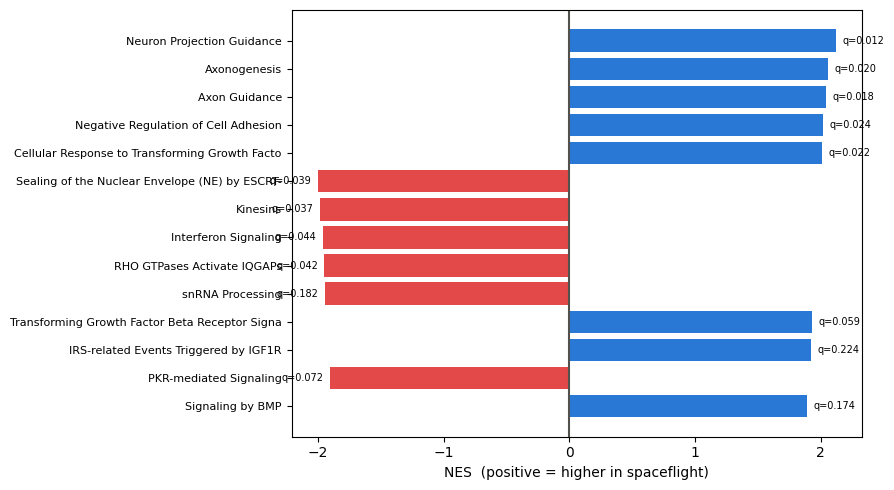

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
top = gs.reindex(gs.NES.abs().sort_values(ascending=False).index).head(14).iloc[::-1]
ax.barh(range(len(top)), top.NES,
        color=["#2a78d6" if v > 0 else "#e34948" for v in top.NES])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([t.split(" (GO:")[0][:46] for t in top.Term], fontsize=8)
for i, (n, q) in enumerate(zip(top.NES, top["FDR q-val"])):
    ax.text(n + (0.05 if n > 0 else -0.05), i, f"q={q:.3f}", va="center",
            ha="left" if n > 0 else "right", fontsize=7)
ax.axvline(0, color="#52514e"); ax.set_xlabel("NES  (positive = higher in spaceflight)")
plt.tight_layout(); plt.show()

### Leading-edge heatmaps

Note `terms.iloc[i]`, not `terms.iloc[0]` — the previous notebook titled all eleven
heatmaps with the name of the first term.

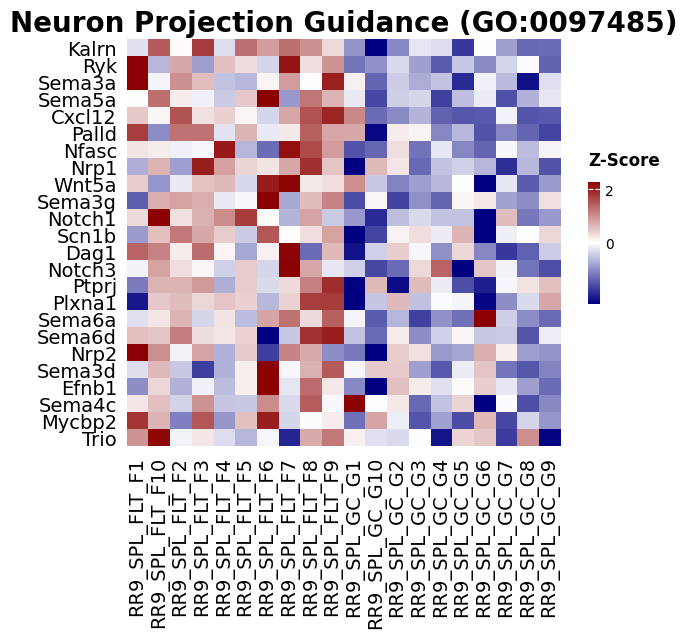

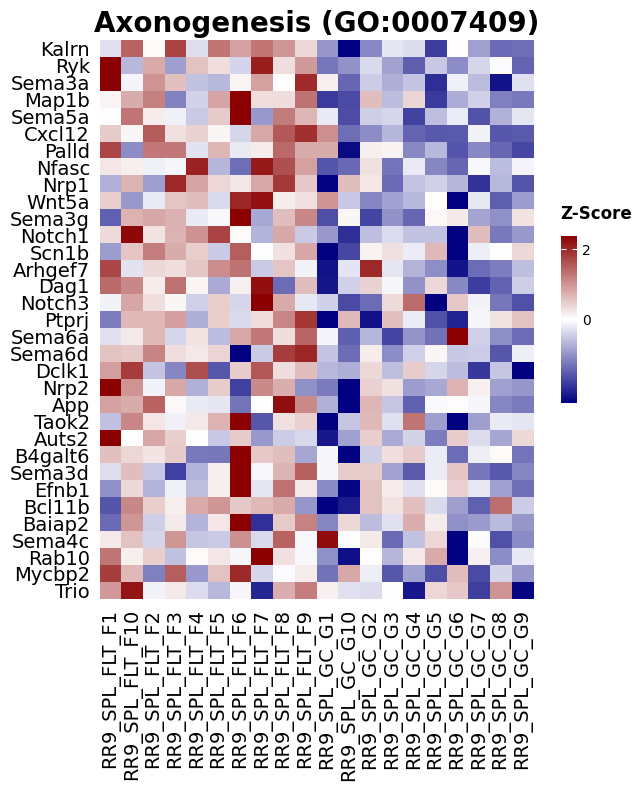

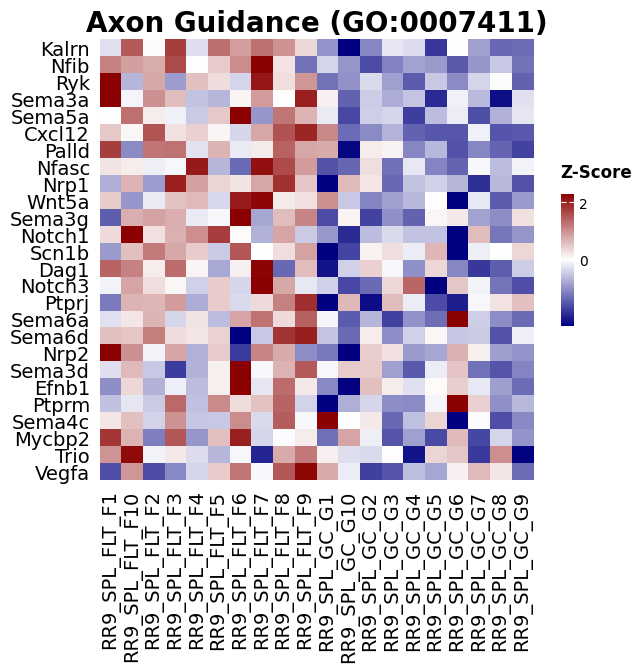

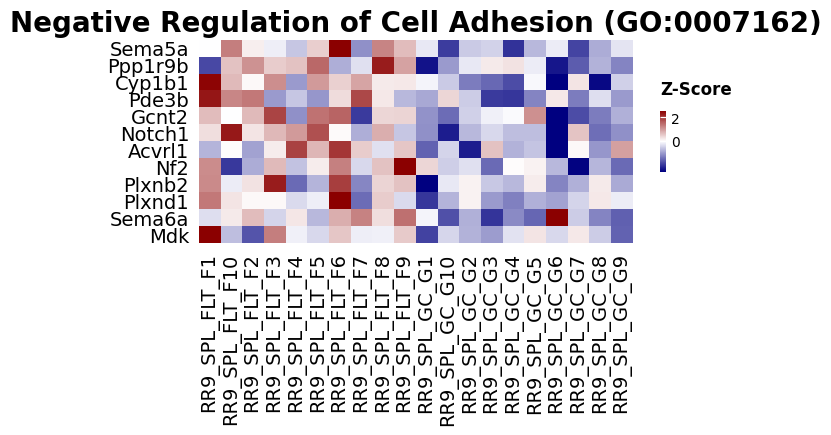

In [6]:
from gseapy import heatmap
show = gs.head(4)
for i in range(len(show)):
    term = show.Term.iloc[i]
    genes = [UP[x.strip().upper()] for x in str(show.Lead_genes.iloc[i]).split(";")
             if x.strip().upper() in UP]
    sub = expr.loc[[gene for gene in genes if gene in expr.index]]
    if len(sub) < 2: continue
    heatmap(df=sub, z_score=0, title=term, figsize=(7, max(2, 0.22 * len(sub))))
    plt.show()

## Over-representation analysis

Correct background, up and down analysed separately, fold enrichment reported, and any term
resting on fewer than three of your genes discarded.

In [7]:
# effective set sizes, restricted to the tested background -- this is the size that matters
bgset = set(x.upper() for x in background)
SETSIZE = {}
for lib in LIBS:
    for term, genes in gp.get_library(name=lib, organism="Mouse").items():
        SETSIZE[(lib, term)] = len(bgset & set(x.upper() for x in genes))

frames = []
for tag, lst in [("UP_in_flight", up_list), ("DOWN_in_flight", dn_list)]:
    if len(lst) < 5: continue
    e = gp.enrichr(gene_list=lst, gene_sets=LIBS, organism="mouse",
                   background=background, outdir=None)          # <-- the fixed line
    d = e.results.copy(); d["direction"] = tag
    d["n_overlap"] = d.Genes.apply(lambda g: len([x for x in str(g).split(";") if x.strip()]))
    d["set_size"]  = [SETSIZE.get((gs_, t_), np.nan) for gs_, t_ in zip(d.Gene_set, d.Term)]
    d["Overlap"]   = d.n_overlap.astype(str) + "/" + d.set_size.astype("Int64").astype(str)
    d["fold_enrichment"] = (d.n_overlap / len(lst)) / (d.set_size / len(background))
    frames.append(d)

o = pd.concat(frames, ignore_index=True)
ora = o[(o["Adjusted P-value"] < ALPHA) & (o.n_overlap >= MIN_OVERLAP) &
        (o.set_size.between(MIN_SET, MAX_SET))].sort_values("Adjusted P-value")
ora.to_csv(f"{OUT}/pathways/ora_significant.csv", index=False)
print(f"{len(ora)} terms pass adj p < {ALPHA}, overlap >= {MIN_OVERLAP}, set size {MIN_SET}-{MAX_SET}")
display(ora[["direction","Term","Overlap","fold_enrichment","Odds Ratio","Adjusted P-value","Genes"]].head(25))
print("Fold enrichment below 1 means NEGATIVELY enriched -- it is a ratio, not a log2 value.")

65 terms pass adj p < 0.05, overlap >= 3, set size 15-300


,direction,Term,Overlap,fold_enrichment,Odds Ratio,Adjusted P-value,Genes
2189,DOWN_in_flight,heme Metabolism,7/152,7.709064,8.912069,0.000728,GYPA;GLRX5;MKRN1;HMBS;CTSE;TRIM10;CDR2
0,UP_in_flight,Positive Regulation of Cell Motility (GO:2000147),9/141,8.110228,9.518735,0.000821,SEMA5A;HSPA8;PDGFRA;XBP1;BMP2;CXCL12;SEMA3A;KD...
1,UP_in_flight,Regulation of Cell Migration (GO:0030334),12/276,5.524358,6.529449,0.000821,SEMA5A;HSPA8;CLDN5;PDGFRA;XBP1;BMP2;CXCL12;TNX...
3,UP_in_flight,Axon Guidance (GO:0007411),6/60,12.706024,15.020202,0.001927,SEMA5A;CXCL12;PALLD;NFIB;SEMA3A;KALRN
5,UP_in_flight,Positive Regulation of Vasculature Development...,6/69,11.048717,12.863327,0.002907,SEMA5A;XBP1;CXCL12;LRG1;KDR;CYP1B1
6,UP_in_flight,Negative Regulation of Epithelial Cell Prolife...,5/44,14.438664,17.133465,0.003560,NFIB;KLF9;NUPR1;APOE;NR2F2
7,UP_in_flight,Positive Regulation of Developmental Process (...,8/154,6.600532,7.537534,0.003673,XBP1;BMP2;HSP90AB1;CXCL12;TNXB;WT1;KDR;APOE
8,UP_in_flight,Positive Regulation of Apoptotic Process (GO:0...,9/209,5.471494,6.241014,0.003711,DNAJA1;HSPA9;XBP1;BMP2;TSC22D1;WT1;FRZB;CYP1B1...
10,UP_in_flight,Regulation of Transforming Growth Factor Beta ...,6/80,9.529518,10.939628,0.003711,XBP1;BMP2;HSP90AB1;LRG1;TSC22D1;HTRA3
9,UP_in_flight,Positive Regulation of Cell Migration (GO:0030...,9/209,5.471494,6.241014,0.003711,SEMA5A;HSPA8;PDGFRA;XBP1;BMP2;CXCL12;SEMA3A;KD...


Fold enrichment below 1 means NEGATIVELY enriched -- it is a ratio, not a log2 value.


In [8]:
rows = []
for _, r_ in ora.iterrows():
    for gene in str(r_["Genes"]).split(";"):
        k = UP.get(gene.strip().upper())
        if k is not None:
            rows.append({"Term": r_["Term"], "direction": r_["direction"], "Overlap": r_["Overlap"],
                         "fold_enrichment": r_["fold_enrichment"], "adj_p_term": r_["Adjusted P-value"],
                         "gene": k, "log2FC": lookup.loc[k, "log2FoldChange"],
                         "adj_p_gene": lookup.loc[k, "padj"], "baseMean": lookup.loc[k, "baseMean"]})
pd.DataFrame(rows).to_csv(f"{OUT}/pathways/ora_member_genes.csv", index=False)
print(f"wrote {len(rows)} gene-in-term rows -- this is your pathway tracking tab for the worksheet")

wrote 334 gene-in-term rows -- this is your pathway tracking tab for the worksheet


## Tracking table for the DGEA worksheet

The course requires a pathway-analysis tracking tab recording the tool, the exact gene list
used, the term, its statistics, and each hit gene's adjusted p and log₂FC. `ora_member_genes.csv`
and `gsea_leading_edge_genes.csv` are that table — paste them straight in.

**Record which list went into which tool.** Feeding the wrong list gives silently invalid
results, and it is the failure the instructors warn about most.

In [9]:
summary = pd.DataFrame([
    {"tool": "GSEA (gseapy)", "input": f"all {expr.shape[0]:,} tested genes, ranked by signal-to-noise",
     "libraries": "; ".join(LIBS), "settings": f"phenotype permutation x1000, size {MIN_SET}-{MAX_SET}, seed {SEED}",
     "terms_reported": len(gs), "filter": f"FDR q < {FDR_T} AND FWER < {FWER_T}"},
    {"tool": "Enrichr ORA (gseapy)", "input": f"{len(up_list)} up / {len(dn_list)} down, analysed separately",
     "libraries": "; ".join(LIBS), "settings": f"background = {len(background):,} tested genes",
     "terms_reported": len(ora), "filter": f"adj p < {ALPHA}, overlap >= {MIN_OVERLAP}, size {MIN_SET}-{MAX_SET}"},
])
summary.to_csv(f"{OUT}/pathways/analysis_tracking.csv", index=False)
display(summary)

,tool,input,libraries,settings,terms_reported,filter
0,GSEA (gseapy),"all 10,546 tested genes, ranked by signal-to-n...",GO_Biological_Process_2025; GO_Cellular_Compon...,"phenotype permutation x1000, size 15-300, seed 7",25,FDR q < 0.25 AND FWER < 0.25
1,Enrichr ORA (gseapy),"83 up / 63 down, analysed separately",GO_Biological_Process_2025; GO_Cellular_Compon...,"background = 10,546 tested genes",65,"adj p < 0.05, overlap >= 3, size 15-300"
